# **Setup**

## **Imports**

In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## **Loading Data**

In [131]:
base_path = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/'

circuits = pd.read_csv(base_path + 'circuits.csv')
constructor_results = pd.read_csv(base_path + 'constructor_results.csv')
constructor_standings = pd.read_csv(base_path + 'constructor_standings.csv')
constructors = pd.read_csv(base_path + 'constructors.csv')
driver_standings = pd.read_csv(base_path + 'driver_standings.csv')
drivers = pd.read_csv(base_path + 'drivers.csv')
lap_times = pd.read_csv(base_path + 'lap_times.csv')
pit_stops = pd.read_csv(base_path + 'pit_stops.csv')
qualifying = pd.read_csv(base_path + 'qualifying.csv')
races = pd.read_csv(base_path + 'races.csv')
results = pd.read_csv(base_path + 'results.csv')
seasons = pd.read_csv(base_path + 'seasons.csv')
sprint_results = pd.read_csv(base_path + 'sprint_results.csv')
status = pd.read_csv(base_path + 'status.csv')

In [132]:
tables = {
    'circuits': circuits,
    'constructor_results': constructor_results,
    'constructor_standings': constructor_standings,
    'constructors': constructors,
    'driver_standings': driver_standings,
    'drivers': drivers,
    'lap_times': lap_times,
    'pit_stops': pit_stops,
    'qualifying': qualifying,
    'races': races,
    'results': results,
    'seasons': seasons,
    'sprint_results': sprint_results,
    'status': status
}

# **Data Cleaning & Auditing**

## **String Normalization**

In [133]:
# for column in df.columns:
#     if(df[column].dtype == object):
#         df[column] = df[column].str.lower()
#         df[column] = df[column].str.strip()
#         df[column] = df[column].replace(r'^\s*$', np.nan, regex=True)

## **Initial EDA**

Does the results table contain any duplicate race data?:  True
How many?  91
Driver-race combinations with duplicates: 85


########### Missing Columns ####################

qualifying
q2    22
q3    46
dtype: int64


###################### Sentinel Columns ###################

constructor_results
status    12608
dtype: int64

drivers
number    802
code      757
dtype: int64

qualifying
q1     156
q2    4625
q3    6819
dtype: int64

races
time            731
fp1_date       1035
fp1_time       1057
fp2_date       1035
fp2_time       1057
fp3_date       1053
fp3_time       1072
quali_date     1035
quali_time     1057
sprint_date    1107
sprint_time    1110
dtype: int64

results
number                 6
position           10953
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
dtype: int64

sprint_results
position          15
time              20
milliseconds      20
fastestLap         9
fa

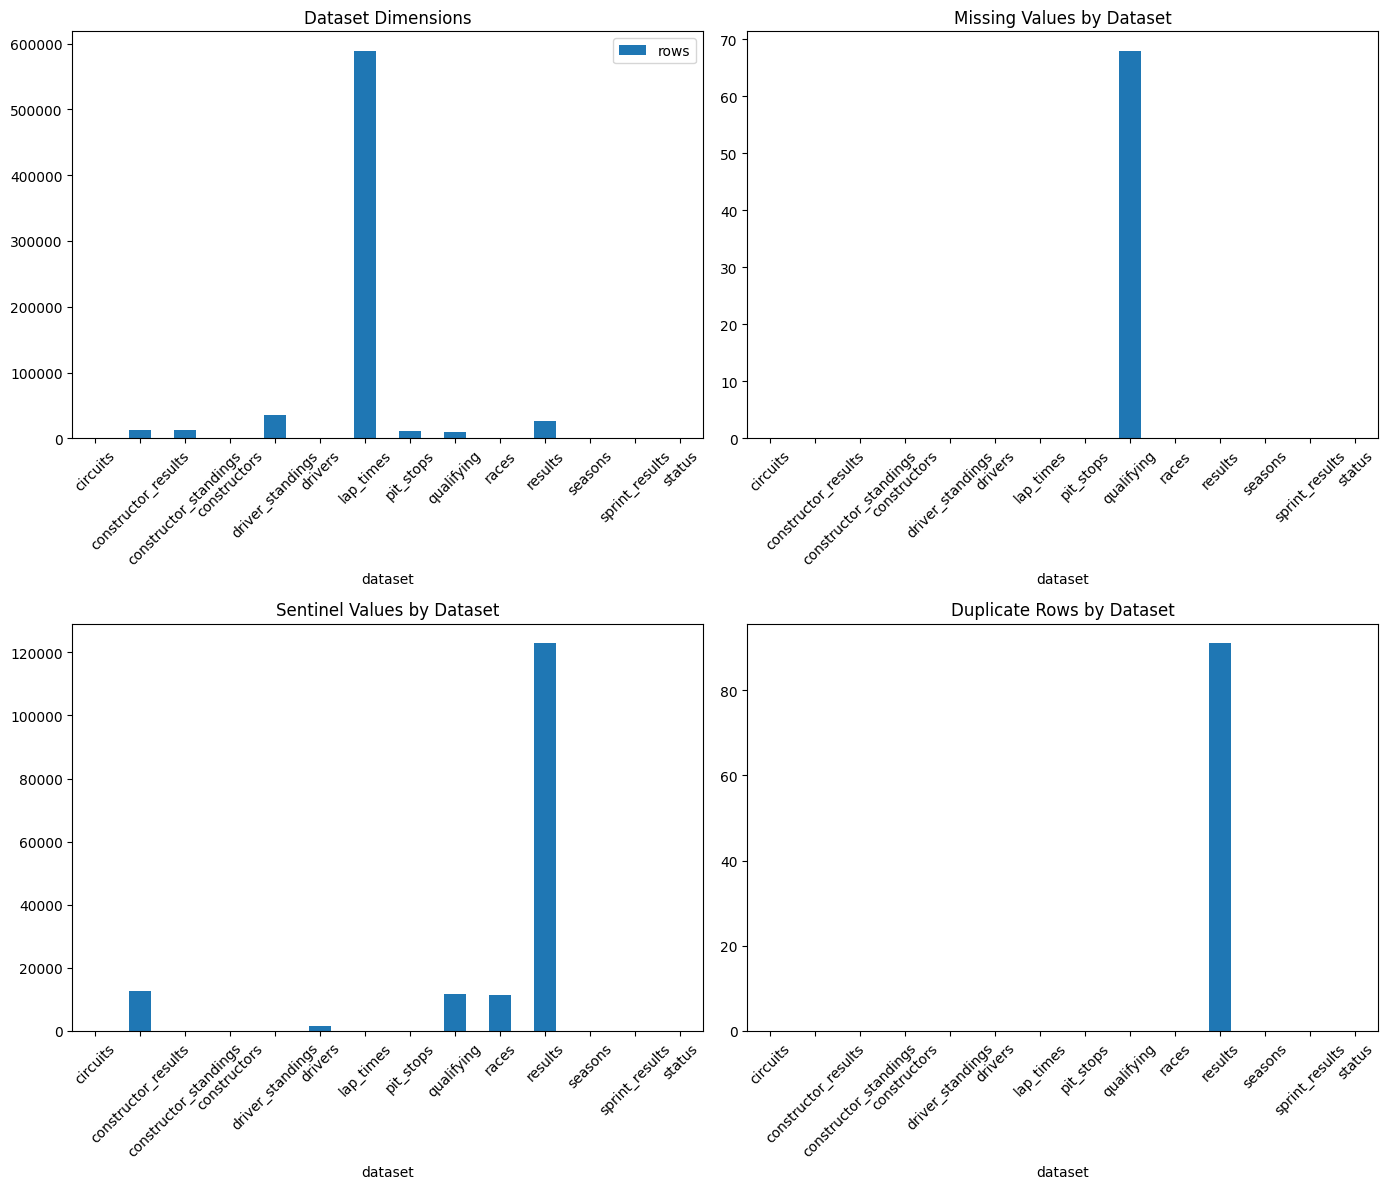

In [134]:
summary = []
missing = []
sentinels = []
duplicates = []

for name, df in tables.items():
    summary.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns)
    })
    
    missing.append({
        "dataset": name,
        "missing_values": df.isna().sum().sum()
    })
    
    sentinels.append({
        "dataset": name,
        "sentinel_values": (df == r"\N").sum().sum()
    })
    
    duplicates.append({
        "dataset": name,
        "duplicates": df.duplicated().sum()
    })


check = bool(results[['raceId', 'driverId']].duplicated().any())
number = results[['raceId', 'driverId']].duplicated().sum()
duplicate_groups = (
    results.groupby(["raceId", "driverId"])
    .size()
)
duplicate_groups = duplicate_groups[duplicate_groups > 1]

for record in duplicates:
    if(record['dataset'] == 'results'):
        record['duplicates'] = number
        break

summary_df = pd.DataFrame(summary)
missing_df = pd.DataFrame(missing)
sentinels_df = pd.DataFrame(sentinels)
duplicates_df = pd.DataFrame(duplicates)

print('Does the results table contain any duplicate race data?: ', check)
print('How many? ', number)
print("Driver-race combinations with duplicates:", len(duplicate_groups))

print('\n')

print('########### Missing Columns ####################')
for name, df in tables.items():
    missing_cols = df.isna().sum()
    missing_cols = missing_cols[missing_cols > 0]

    if len(missing_cols) > 0:
        print(f"\n{name}")
        print(missing_cols)

print('\n')

print('###################### Sentinel Columns ###################')
for name, df in tables.items():
    sentinel_cols = (df == r"\N").sum()
    sentinel_cols = sentinel_cols[sentinel_cols > 0]

    if len(sentinel_cols) > 0:
        print(f"\n{name}")
        print(sentinel_cols)

print('\n')

# Create a 2x2 grid of subplots with a shared figure size
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 12))

# 1. Dataset Dimensions (Top-Left)
summary_df.plot(
    x="dataset",
    y=["rows"],
    kind="bar",
    ax=axes[0, 0],
    title="Dataset Dimensions"
)

# 2. Missing Values (Top-Right)
missing_df.plot(
    x="dataset",
    y="missing_values",
    kind="bar",
    ax=axes[0, 1],
    title="Missing Values by Dataset",
    legend=False
)

# 3. Sentinel Values (Bottom-Left)
sentinels_df.plot(
    x="dataset",
    y="sentinel_values",
    kind="bar",
    ax=axes[1, 0],
    title="Sentinel Values by Dataset",
    legend=False
)

# 4. Duplicate Rows (Bottom-Right)
duplicates_df.plot(
    x="dataset",
    y="duplicates",
    kind="bar",
    ax=axes[1, 1],
    title="Duplicate Rows by Dataset",
    legend=False
)

# Rotate x-axis labels for readability and prevent overlapping titles/labels
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [135]:
for key, value in tables.items():
    print(f'###### {key} #######')
    print(value.info())
    print(value.describe())
    display(value.head(5))

###### circuits #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB
None
       circuitId        lat         lng          alt
count  77.000000  77.000000   77.000000    77.000000
mean   39.883117  33.442925    1.076683   247.012987
std    23.001701  22.808866   65.516951   362.738469
min     1.000000 -37.849700 -118.189000    -7.000000
25%    20.000000  32.777400   -9.394170    18.000000
50%    40.000000  40.951700    3.93083

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


###### constructor_results #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB
None
       constructorResultsId        raceId  constructorId        points
count          12625.000000  12625.000000   12625.000000  12625.000000
mean            8424.500594    528.235802      45.956119      4.053545
std             5666.310522    314.793555      59.468418      7.862202
min                1.000000      1.000000       1.000000      0.000000
25%             3157.000000    287.000000       6.000000      0.000000
50%  

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


###### constructor_standings #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB
None
       constructorStandingsId        raceId  constructorId        points  \
count            13391.000000  13391.000000   13391.000000  13391.000000   
mean             16982.110821    535.399821      49.603390     37.178515   
std               8868.446172    307.705928      61.213953     84.346048   
min  

...

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


###### sprint_results #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   resultId        360 non-null    int64 
 1   raceId          360 non-null    int64 
 2   driverId        360 non-null    int64 
 3   constructorId   360 non-null    int64 
 4   number          360 non-null    int64 
 5   grid            360 non-null    int64 
 6   position        360 non-null    object
 7   positionText    360 non-null    object
 8   positionOrder   360 non-null    int64 
 9   points          360 non-null    int64 
 10  laps            360 non-null    int64 
 11  time            360 non-null    object
 12  milliseconds    360 non-null    object
 13  fastestLap      360 non-null    object
 14  fastestLapTime  360 non-null    object
 15  statusId        360 non-null    int64 
dtypes: int64(10), object(6)
memory usage: 45.1+ KB
None
         resultI

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1


###### status #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB
None
         statusId
count  139.000000
mean    71.237410
std     41.092434
min      1.000000
25%     35.500000
50%     72.000000
75%    106.500000
max    141.000000


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


## **Numerical Columns Casting**

In [136]:
cleaned_tables = {}

def convert_column_to_number(table):
    for column in table.columns:
        new_column = pd.to_numeric(table[column], errors='coerce')
        if new_column.notna().sum() == table[column].notna().sum():
            table[column] = new_column
    return table

# Convert Number Columns To Number Type After Removing \N 
for table_name,table in tables.items():
    cleaned_tables[table_name] = convert_column_to_number(table.replace("\\N", np.nan))

In [137]:
for key, value in cleaned_tables.items():
    print(f'###### {key} #######')
    print(value.info())
    display(value.head(5))

###### circuits #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB
None


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


###### constructor_results #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                17 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB
None


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


###### constructor_standings #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB
None


...

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


###### sprint_results #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    object 
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    object 
 15  statusId        360 non-null    int64  
dtypes: float64(3), int64(10), object(3)
memory usage: 

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


###### status #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB
None


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


## **Date Columns Casting**

In [138]:
# Convert Date Strings To Date Objects
cleaned_tables['races']['date'] = pd.to_datetime(cleaned_tables['races']['date'])
cleaned_tables['drivers']['dob'] = pd.to_datetime(cleaned_tables['drivers']['dob'])

In [139]:
# Convert Lap Times To Seconds
def time_to_seconds(text):
    if pd.isna(text):
        return np.nan
    minutes, seconds = text.split(':')
    return float(minutes) * 60 + float(seconds)


for col in ['q1', 'q2', 'q3']:
    cleaned_tables['qualifying'][col] = cleaned_tables['qualifying'][col].map(time_to_seconds)

## **Lap Times to Seconds Normalization**

In [140]:
cleaned_tables['qualifying'].head()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,86.572,85.187,86.714
1,2,18,9,2,4,2,86.103,85.315,86.869
2,3,18,5,1,23,3,85.664,85.452,87.079
3,4,18,13,6,2,4,85.994,85.691,87.178
4,5,18,2,2,3,5,85.960,85.518,87.236


## **Referential Integrity**

In [141]:
# Create Composite Primary Keys
cleaned_tables['lap_times']['lapId'] = (cleaned_tables['lap_times']['raceId'].astype(str) + '_' + cleaned_tables['lap_times']['driverId'].astype(str) + '_' + cleaned_tables['lap_times']['lap'].astype(str))
cleaned_tables['pit_stops']['stopId'] = (cleaned_tables['pit_stops']['raceId'].astype(str) + '_' + cleaned_tables['pit_stops']['driverId'].astype(str) + '_' + cleaned_tables['pit_stops']['stop'].astype(str))

primary_keys = {
    'circuits': 'circuitId', 
    'constructor_results': 'constructorResultsId', 
    'constructor_standings': 'constructorStandingsId',
    'constructors': 'constructorId', 
    'driver_standings': 'driverStandingsId', 
    'drivers': 'driverId',
    'lap_times': 'lapId',
    'pit_stops': 'stopId',
    'qualifying': 'qualifyId', 
    'races': 'raceId',
    'results': 'resultId', 
    'seasons': 'year',
    'sprint_results': 'resultId',
    'status': 'statusId', 
}


for table_name, key in primary_keys.items():
    unique = cleaned_tables[table_name][key].is_unique
    no_missing = cleaned_tables[table_name][key].notna().all()
    print(f'{table_name}.{key}: \n unique = {unique} \n no missing = {no_missing}')

circuits.circuitId: 
 unique = True 
 no missing = True
constructor_results.constructorResultsId: 
 unique = True 
 no missing = True
constructor_standings.constructorStandingsId: 
 unique = True 
 no missing = True
constructors.constructorId: 
 unique = True 
 no missing = True
driver_standings.driverStandingsId: 
 unique = True 
 no missing = True
drivers.driverId: 
 unique = True 
 no missing = True
lap_times.lapId: 
 unique = True 
 no missing = True
pit_stops.stopId: 
 unique = True 
 no missing = True
qualifying.qualifyId: 
 unique = True 
 no missing = True
races.raceId: 
 unique = True 
 no missing = True
results.resultId: 
 unique = True 
 no missing = True
seasons.year: 
 unique = True 
 no missing = True
sprint_results.resultId: 
 unique = True 
 no missing = True
status.statusId: 
 unique = True 
 no missing = True


In [142]:
foreign_keys = [
    
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),

    ('constructor_standings', 'raceId', 'races', 'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),

    ('driver_standings', 'raceId', 'races', 'raceId'),
    ('driver_standings', 'driverId', 'drivers', 'driverId'),

    ('lap_times', 'raceId', 'races', 'raceId'),
    ('lap_times', 'driverId', 'drivers', 'driverId'),

    
    ('pit_stops', 'raceId', 'races', 'raceId'),
    ('pit_stops', 'driverId', 'drivers', 'driverId'),

    ('qualifying', 'raceId', 'races', 'raceId'),
    ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'constructorId', 'constructors', 'constructorId'),

    ('races', 'circuitId', 'circuits', 'circuitId'),

    ('results', 'raceId', 'races', 'raceId'),
    ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'),
    ('results', 'statusId', 'status', 'statusId'),


    ('sprint_results', 'raceId', 'races', 'raceId'),
    ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'statusId', 'status', 'statusId'),
    
]

for table, column, parent, parent_key in foreign_keys:
    # ~ means 'not'
    missing = ~ cleaned_tables[table][column].isin(cleaned_tables[parent][parent_key])
    print(f'{table}.{column} -> {parent}: {missing.sum()} values not found')

constructor_results.raceId -> races: 0 values not found
constructor_results.constructorId -> constructors: 0 values not found
constructor_standings.raceId -> races: 0 values not found
constructor_standings.constructorId -> constructors: 0 values not found
driver_standings.raceId -> races: 0 values not found
driver_standings.driverId -> drivers: 0 values not found
lap_times.raceId -> races: 0 values not found
lap_times.driverId -> drivers: 0 values not found
pit_stops.raceId -> races: 0 values not found
pit_stops.driverId -> drivers: 0 values not found
qualifying.raceId -> races: 0 values not found
qualifying.driverId -> drivers: 0 values not found
qualifying.constructorId -> constructors: 0 values not found
races.circuitId -> circuits: 0 values not found
results.raceId -> races: 0 values not found
results.driverId -> drivers: 0 values not found
results.constructorId -> constructors: 0 values not found
results.statusId -> status: 0 values not found
sprint_results.raceId -> races: 0 valu

## **Post Cleaning EDA**

Does the results table contain any duplicate race data?:  {np.True_}
How many?  91
Driver-race combinations with duplicates: 85

########### Missing Columns ####################

constructor_results
status    12608
dtype: int64

drivers
number    802
code      757
dtype: int64

qualifying
q1     156
q2    4647
q3    6865
dtype: int64

races
time            731
fp1_date       1035
fp1_time       1057
fp2_date       1035
fp2_time       1057
fp3_date       1053
fp3_time       1072
quali_date     1035
quali_time     1057
sprint_date    1107
sprint_time    1110
dtype: int64

results
number                 6
position           10953
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
dtype: int64

sprint_results
position          15
time              20
milliseconds      20
fastestLap         9
fastestLapTime     9
dtype: int64

###################### Sentinel Columns ###################


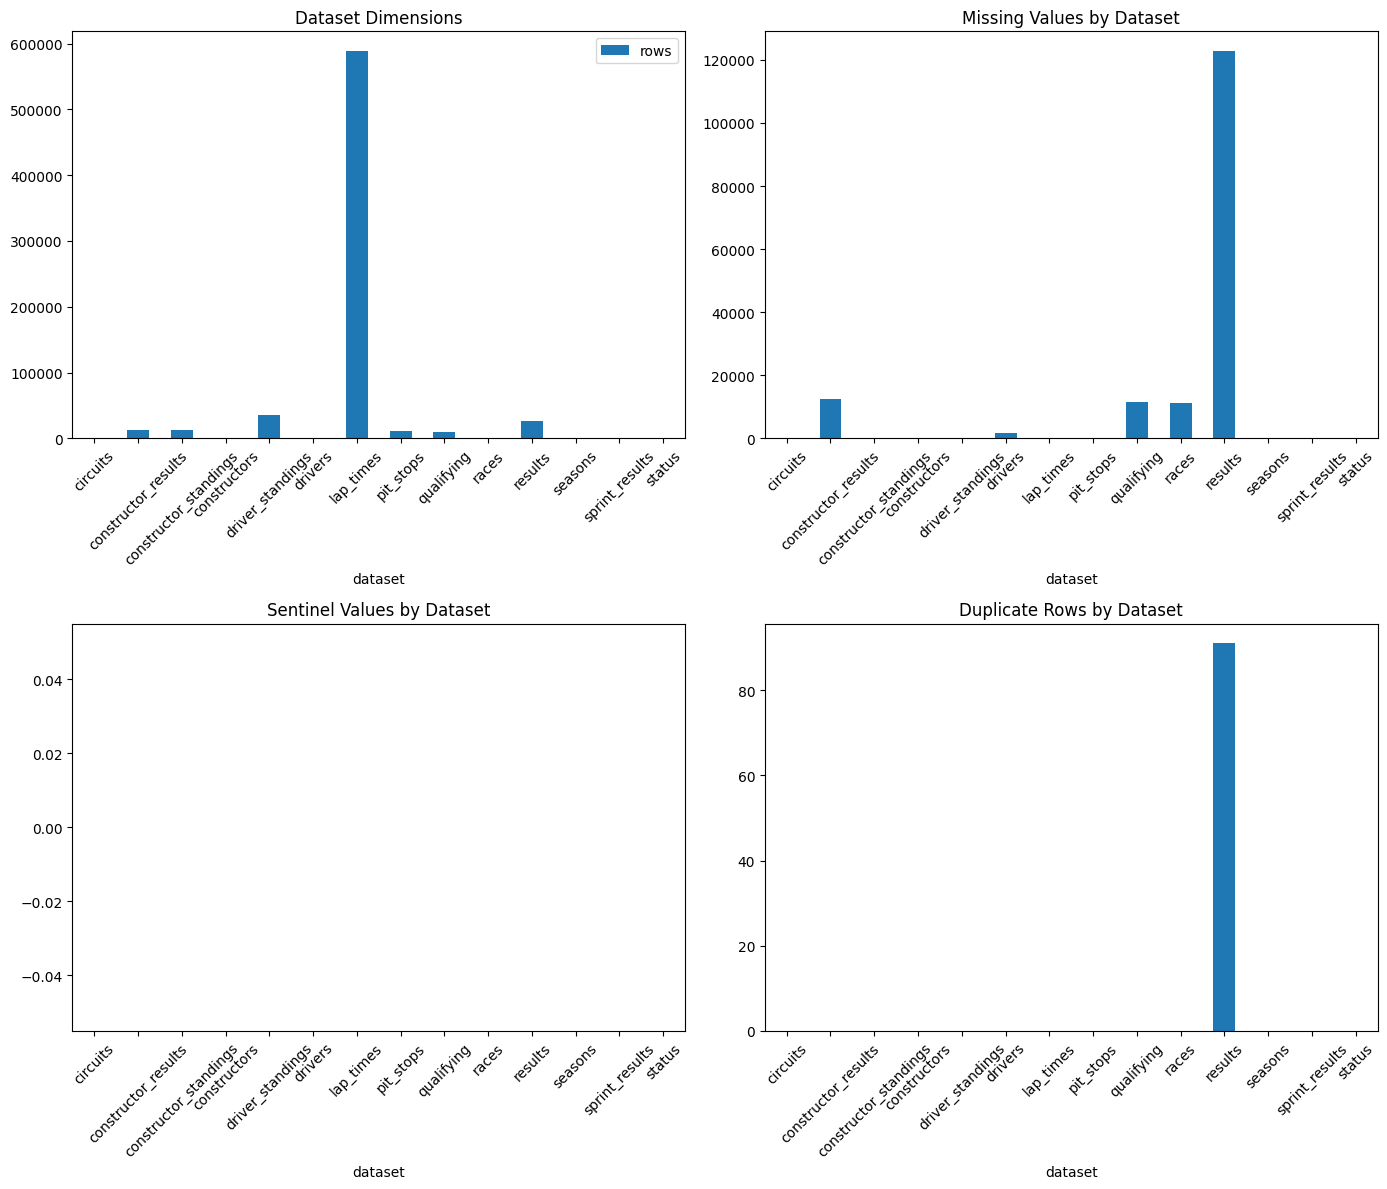

In [146]:
summary = []
missing = []
sentinels = []
duplicates = []

for name, df in cleaned_tables.items():
    summary.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns)
    })

    missing.append({
        "dataset": name,
        "missing_values": df.isna().sum().sum()
    })

    sentinels.append({
        "dataset": name,
        "sentinel_values": (df == r"\N").sum().sum()
    })

    duplicates.append({
        "dataset": name,
        "duplicates": df.duplicated().sum()
    })


check = results[['raceId', 'driverId']].duplicated().any()
number = results[['raceId', 'driverId']].duplicated().sum()
duplicate_groups = (
    results.groupby(["raceId", "driverId"])
    .size()
)
duplicate_groups = duplicate_groups[duplicate_groups > 1]

for record in duplicates:
    if(record['dataset'] == 'results'):
        record['duplicates'] = number
        break


summary_df = pd.DataFrame(summary)
missing_df = pd.DataFrame(missing)
sentinels_df = pd.DataFrame(sentinels)
duplicates_df = pd.DataFrame(duplicates)


print('Does the results table contain any duplicate race data?: ', {check})
print('How many? ', number)
print("Driver-race combinations with duplicates:", len(duplicate_groups))


print('')
print('########### Missing Columns ####################')
for name, df in cleaned_tables.items():
    missing_cols = df.isna().sum()
    missing_cols = missing_cols[missing_cols > 0]

    if len(missing_cols) > 0:
        print(f"\n{name}")
        print(missing_cols)

print("")
print('###################### Sentinel Columns ###################')
for name, df in cleaned_tables.items():
    sentinel_cols = (df == r"\N").sum()
    sentinel_cols = sentinel_cols[sentinel_cols > 0]

    if len(sentinel_cols) > 0:
        print(f"\n{name}")
        print(sentinel_cols)


# Create a 2x2 grid of subplots with a shared figure size
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 12))

# 1. Dataset Dimensions (Top-Left)
summary_df.plot(
    x="dataset",
    y=["rows"],
    kind="bar",
    ax=axes[0, 0],
    title="Dataset Dimensions"
)

# 2. Missing Values (Top-Right)
missing_df.plot(
    x="dataset",
    y="missing_values",
    kind="bar",
    ax=axes[0, 1],
    title="Missing Values by Dataset",
    legend=False
)

# 3. Sentinel Values (Bottom-Left)
sentinels_df.plot(
    x="dataset",
    y="sentinel_values",
    kind="bar",
    ax=axes[1, 0],
    title="Sentinel Values by Dataset",
    legend=False
)

# 4. Duplicate Rows (Bottom-Right)
duplicates_df.plot(
    x="dataset",
    y="duplicates",
    kind="bar",
    ax=axes[1, 1],
    title="Duplicate Rows by Dataset",
    legend=False
)

# Rotate x-axis labels for readability and prevent overlapping titles/labels
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [147]:
# for name, table in cleaned_tables.items():
#     print(f"=========== {name} ===========")
#     display(table.head(1))

display(cleaned_tables['races'].head(1))
display(cleaned_tables['circuits'].head(1))
display(cleaned_tables['results'].head(1))
display(cleaned_tables['drivers'].head(1))
display(cleaned_tables['constructor_standings'].head(1))

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.3,1


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton


,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1


In [143]:
modeling_data = (
    cleaned_tables['races'].drop(columns=['name', 'year', 'date', 'time', 'url', 'quali_date', 'quali_time', 'fp1_time', 'fp2_time', 'fp3_time', 'fp1_date', 'fp2_date', 'fp3_date', 'sprint_time', 'sprint_date'])
    .merge(cleaned_tables['circuits'].drop(columns=['circuitRef', 'name', 'location', 'lat', 'lng', 'alt', 'url']), on='circuitId')
    .merge(cleaned_tables['results'].drop(columns=['number', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'resultId']), on='raceId')
    .merge(cleaned_tables['drivers'].drop(columns=['driverRef', 'number', 'code', 'forename', 'surname', 'dob', 'url']), on='driverId')
)

modeling_data.info()
modeling_data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   raceId         26759 non-null  int64  
 1   round          26759 non-null  int64  
 2   circuitId      26759 non-null  int64  
 3   country        26759 non-null  object 
 4   driverId       26759 non-null  int64  
 5   constructorId  26759 non-null  int64  
 6   grid           26759 non-null  int64  
 7   position       15806 non-null  float64
 8   positionText   26759 non-null  object 
 9   positionOrder  26759 non-null  int64  
 10  nationality    26759 non-null  object 
dtypes: float64(1), int64(7), object(3)
memory usage: 2.2+ MB


,raceId,round,circuitId,country,driverId,constructorId,grid,position,positionText,positionOrder,nationality
0,1,1,1,Australia,18,23,1,1.0,1,1,British
1,1,1,1,Australia,22,23,2,2.0,2,2,Brazilian
2,1,1,1,Australia,15,7,20,3.0,3,3,Italian
3,1,1,1,Australia,10,7,19,4.0,4,4,German
4,1,1,1,Australia,4,4,10,5.0,5,5,Spanish
...,...,...,...,...,...,...,...,...,...,...,...
26754,1144,24,24,UAE,825,210,14,16.0,16,16,Danish
26755,1144,24,24,UAE,859,215,12,17.0,17,17,New Zealander
26756,1144,24,24,UAE,822,15,9,NaN,R,18,Finnish
26757,1144,24,24,UAE,861,3,20,NaN,R,19,Argentinian


## **Duplicate (Shared Drive) Handling**

In [144]:
# all duplicates
duplicates = modeling_data[modeling_data.duplicated(['raceId', 'driverId'], keep=False)]
duplicates

,raceId,round,circuitId,country,driverId,constructorId,grid,position,positionText,positionOrder,nationality
13664,540,14,14,Italy,229,54,0,NaN,F,26,Austrian
13667,540,14,14,Italy,229,57,0,NaN,F,29,Austrian
17819,717,9,46,USA,373,172,1,7.0,7,7,British
17832,717,9,46,USA,373,172,1,NaN,R,12,British
18221,733,5,58,UK,465,172,0,NaN,W,22,British
...,...,...,...,...,...,...,...,...,...,...,...
20749,838,6,55,France,627,154,15,6.0,6,6,French
20764,839,7,14,Italy,579,51,1,NaN,R,15,Argentine
20766,839,7,14,Italy,647,6,2,NaN,R,17,Italian
20777,839,7,14,Italy,647,6,6,2.0,2,2,Italian


In [145]:
# we chose to keep last since he is the one finishing the race 
filtered_duplicates = modeling_data[modeling_data.duplicated(['raceId', 'driverId'], keep='last')]
filtered_duplicates

,raceId,round,circuitId,country,driverId,constructorId,grid,position,positionText,positionOrder,nationality
13664,540,14,14,Italy,229,54,0,NaN,F,26,Austrian
17819,717,9,46,USA,373,172,1,7.0,7,7,British
18221,733,5,58,UK,465,172,0,NaN,W,22,British
18442,742,5,58,UK,475,102,20,NaN,D,19,British
18544,745,8,46,USA,418,172,11,NaN,R,17,American
...,...,...,...,...,...,...,...,...,...,...,...
20591,831,7,14,Italy,642,51,2,NaN,R,16,Italian
20693,835,3,19,USA,529,150,8,NaN,R,31,American
20741,838,6,55,France,627,154,6,NaN,R,12,French
20764,839,7,14,Italy,579,51,1,NaN,R,15,Argentine


In [148]:
modeling_data = modeling_data.drop(filtered_duplicates.index)
modeling_data

,raceId,round,circuitId,country,driverId,constructorId,grid,position,positionText,positionOrder,nationality
0,1,1,1,Australia,18,23,1,1.0,1,1,British
1,1,1,1,Australia,22,23,2,2.0,2,2,Brazilian
2,1,1,1,Australia,15,7,20,3.0,3,3,Italian
3,1,1,1,Australia,10,7,19,4.0,4,4,German
4,1,1,1,Australia,4,4,10,5.0,5,5,Spanish
...,...,...,...,...,...,...,...,...,...,...,...
26754,1144,24,24,UAE,825,210,14,16.0,16,16,Danish
26755,1144,24,24,UAE,859,215,12,17.0,17,17,New Zealander
26756,1144,24,24,UAE,822,15,9,NaN,R,18,Finnish
26757,1144,24,24,UAE,861,3,20,NaN,R,19,Argentinian


# **Data Engineering Questions**

In [149]:
mask = (cleaned_tables['results']['grid'] <= 2) & (cleaned_tables['results']['position'] <= 3)

merged_before_2014 = (
    results[mask]
    .merge(cleaned_tables['races'][cleaned_tables['races']['year'] <= 2014][['raceId', 'circuitId']], on='raceId')
    .merge(cleaned_tables['circuits'][['circuitId', 'name']], on='circuitId')
)

merged_after_2014 = (
    results[mask]
    .merge(cleaned_tables['races'][cleaned_tables['races']['year'] >= 2014][['raceId', 'circuitId']], on='raceId')
    .merge(cleaned_tables['circuits'][['circuitId', 'name']], on='circuitId')
)

df_before_2014 = (
    merged_before_2014.groupby('name')
    .size()
    .sort_values(ascending=False)
    .rename('num')
    .reset_index()
    .rename(columns={'name': 'circuit'})
)



df_after_2014 = (
    merged_after_2014.groupby('name')
    .size()
    .sort_values(ascending=False)
    .rename('num')
    .reset_index()
    .rename(columns={'name': 'circuit'})
)

print(f"=====================================================")
print(f"BEFORE 2014")
display(df_before_2014)
print(f"=====================================================")
print(f"=====================================================")
print(f"AFTER 2014")
display(df_after_2014)
print(f"=====================================================")

BEFORE 2014


,circuit,num
0,Autodromo Nazionale di Monza,62
1,Circuit de Monaco,61
2,Silverstone Circuit,53
3,Circuit de Spa-Francorchamps,50
4,Nürburgring,45
...,...,...
63,Le Mans,1
64,Monsanto Park Circuit,1
65,Montjuïc,1
66,Las Vegas Street Circuit,1


AFTER 2014


,circuit,num
0,Red Bull Ring,19
1,Yas Marina Circuit,19
2,Circuit de Barcelona-Catalunya,18
3,Circuit de Spa-Francorchamps,18
4,Silverstone Circuit,18
5,Circuit de Monaco,17
6,Circuit of the Americas,16
7,Autodromo Nazionale di Monza,16
8,Suzuka Circuit,16
9,Bahrain International Circuit,16


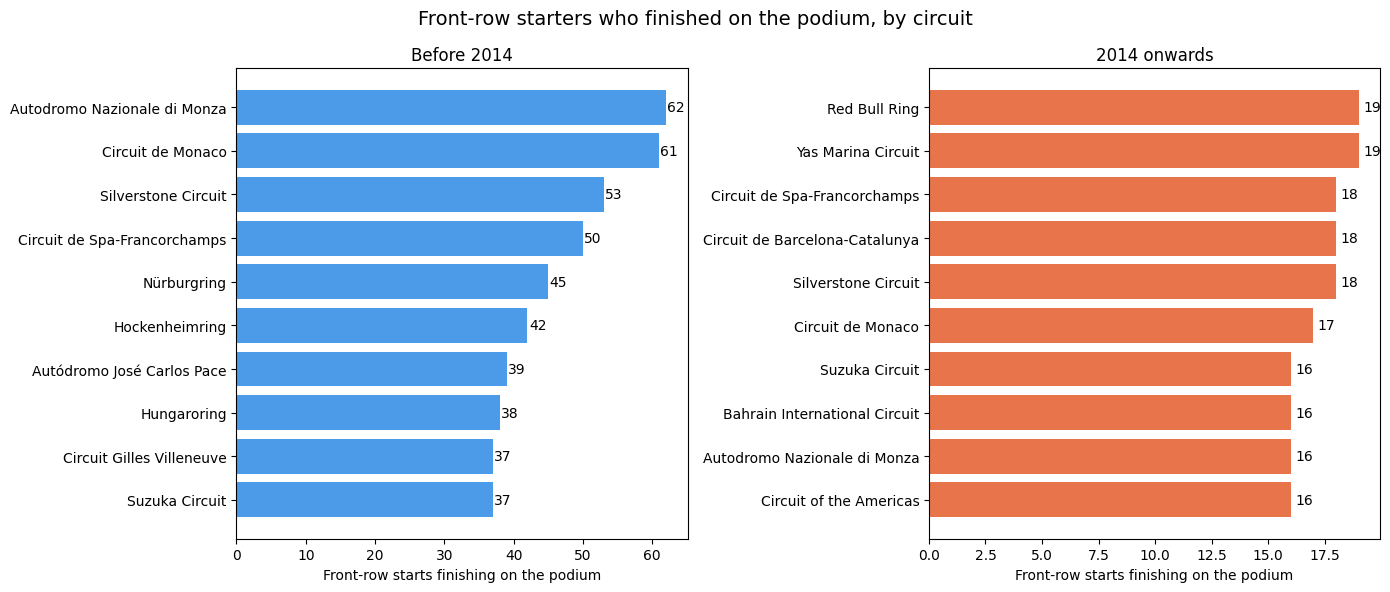

In [150]:
top = 10
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, df, title, color in [
    (axes[0], df_before_2014, 'Before 2014', '#4c9be8'),
    (axes[1], df_after_2014,  '2014 onwards', '#e8744c'),
]:
    data = df.head(top).sort_values('num')   # sort so the biggest bar ends up on top
    ax.barh(data['circuit'], data['num'], color=color)
    ax.set_title(title)
    ax.set_xlabel('Front-row starts finishing on the podium')
    for i, v in enumerate(data['num']):
        ax.text(v + 0.2, i, str(v), va='center')   # value labels

fig.suptitle('Front-row starters who finished on the podium, by circuit', fontsize=14)
plt.tight_layout()
plt.show()

In [151]:
nat_to_country = {
    'American': 'USA',
    'American-Italian': 'USA',
    'Argentine': 'Argentina',
    'Argentine-Italian': 'Argentina',
    'Argentinian ': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'East German': 'East Germany',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'Zimbabwe',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela',
}


df = (
    cleaned_tables['results'][['raceId','position','grid','driverId']]
    .merge(cleaned_tables['races'][['raceId','circuitId']] , on='raceId')
    .merge(cleaned_tables['drivers'][['driverId','nationality']], on='driverId')
    .merge(cleaned_tables['circuits'][['circuitId','country']], on='circuitId')
)

df['driver_country'] = df['nationality'].map(nat_to_country)

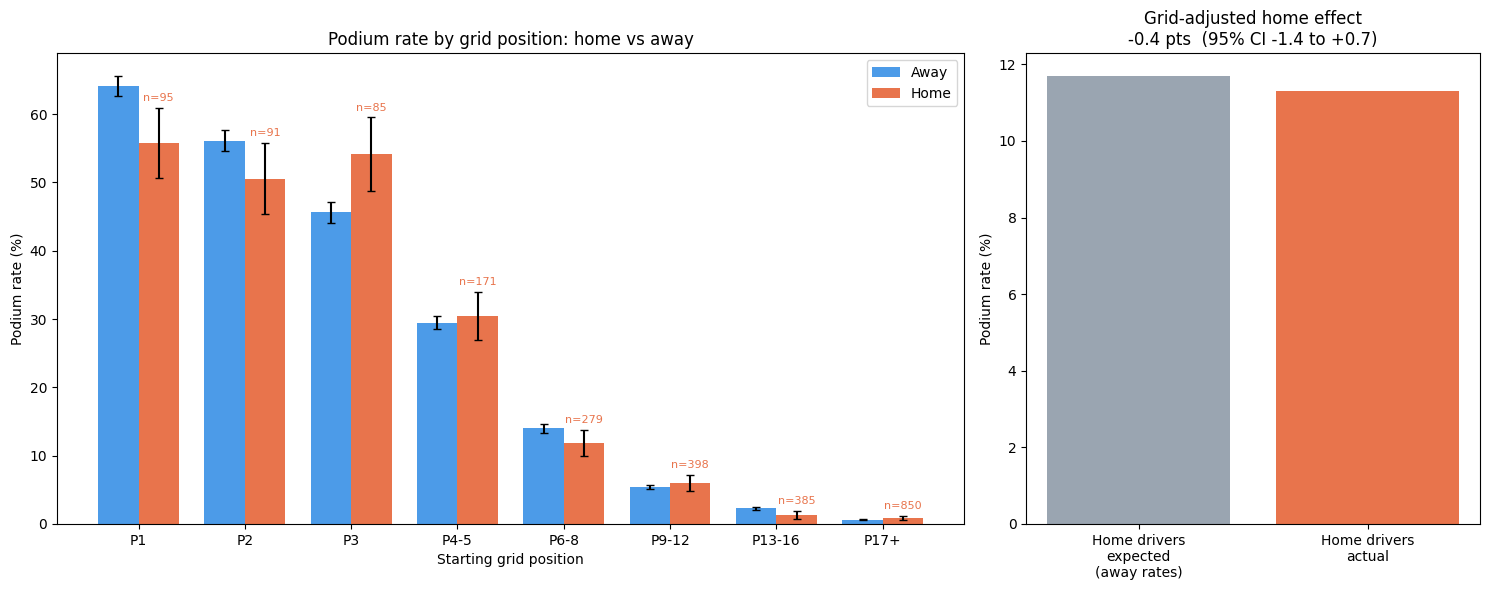

In [152]:
d = df.copy()
d = d[d['grid'] >= 1]                                  # drop pit-lane starts (grid == 0)
d['home']   = d['driver_country'] == d['country']
d['podium'] = (d['position'] <= 3)                     # NaN (DNF) -> False

bins   = [0, 1, 2, 3, 5, 8, 12, 16, 40]
labels = ['P1', 'P2', 'P3', 'P4-5', 'P6-8', 'P9-12', 'P13-16', 'P17+']
d['grid_bin'] = pd.cut(d['grid'], bins=bins, labels=labels)

# podium rate per grid bin, split by home/away
g = (d.groupby(['grid_bin', 'home'], observed=True)['podium']
       .agg(rate='mean', k='sum', n='size')
       .unstack('home'))

# standard error for error bars
def se(rate, n): return np.sqrt(rate * (1 - rate) / n)

# grid-adjusted effect: actual home podium rate vs the rate home drivers
# would have had if they converted like away drivers from the same grid bin
def adjusted_effect(data):
    t = data.groupby(['grid_bin', 'home'], observed=True)['podium'].agg(['mean', 'size']).unstack('home')
    t = t.dropna()
    w = t[('size', True)]
    expected = (t[('mean', False)] * w).sum() / w.sum()
    actual   = (t[('mean', True)]  * w).sum() / w.sum()
    return actual, expected

actual, expected = adjusted_effect(d)

# bootstrap CI for (actual - expected)
rng = np.random.default_rng(0)
boots = []
for _ in range(500):
    s = d.sample(len(d), replace=True, random_state=int(rng.integers(1e9)))
    a, e = adjusted_effect(s)
    boots.append(a - e)
lo, hi = np.percentile(boots, [2.5, 97.5])

# ---- plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [2, 1]})

x = np.arange(len(g))
wd = 0.38
away_rate, home_rate = g[('rate', False)] * 100, g[('rate', True)] * 100
away_err = se(g[('rate', False)], g[('n', False)]) * 100
home_err = se(g[('rate', True)],  g[('n', True)])  * 100

ax1.bar(x - wd/2, away_rate, wd, yerr=away_err, color='#4c9be8', label='Away', capsize=3)
ax1.bar(x + wd/2, home_rate, wd, yerr=home_err, color='#e8744c', label='Home', capsize=3)
for i, (_, r) in enumerate(g.iterrows()):
    ax1.text(i + wd/2, home_rate.iloc[i] + home_err.iloc[i] + 1, f"n={int(r[('n', True)])}",
             ha='center', fontsize=8, color='#e8744c')
ax1.set_xticks(x)
ax1.set_xticklabels(g.index)
ax1.set_xlabel('Starting grid position')
ax1.set_ylabel('Podium rate (%)')
ax1.set_title('Podium rate by grid position: home vs away')
ax1.legend()

ax2.bar(['Home drivers\nexpected\n(away rates)', 'Home drivers\nactual'],
        [expected * 100, actual * 100], color=['#9aa5b1', '#e8744c'])
ax2.set_ylabel('Podium rate (%)')
ax2.set_title(f'Grid-adjusted home effect\n{(actual-expected)*100:+.1f} pts  (95% CI {lo*100:+.1f} to {hi*100:+.1f})')

plt.tight_layout()
plt.show()

In [153]:
df = cleaned_tables['results'][['raceId', 'statusId','constructorId']].merge(cleaned_tables['status'], on='statusId').merge(cleaned_tables['constructors'][['constructorId', 'name']], on='constructorId').merge(cleaned_tables['races'][['raceId', 'year']], on='raceId')

mechanical_failures = ['Engine', 'Gearbox', 'Hydraulics']

all_races_by_constructor = df[df['status'].isin(mechanical_failures)]

r_2014_2021 = all_races_by_constructor[all_races_by_constructor['year'].between(2014, 2021)]
r_2022_2024 = all_races_by_constructor[all_races_by_constructor['year'].between(2022, 2024)]

# r_2014_2021.groupby('name')

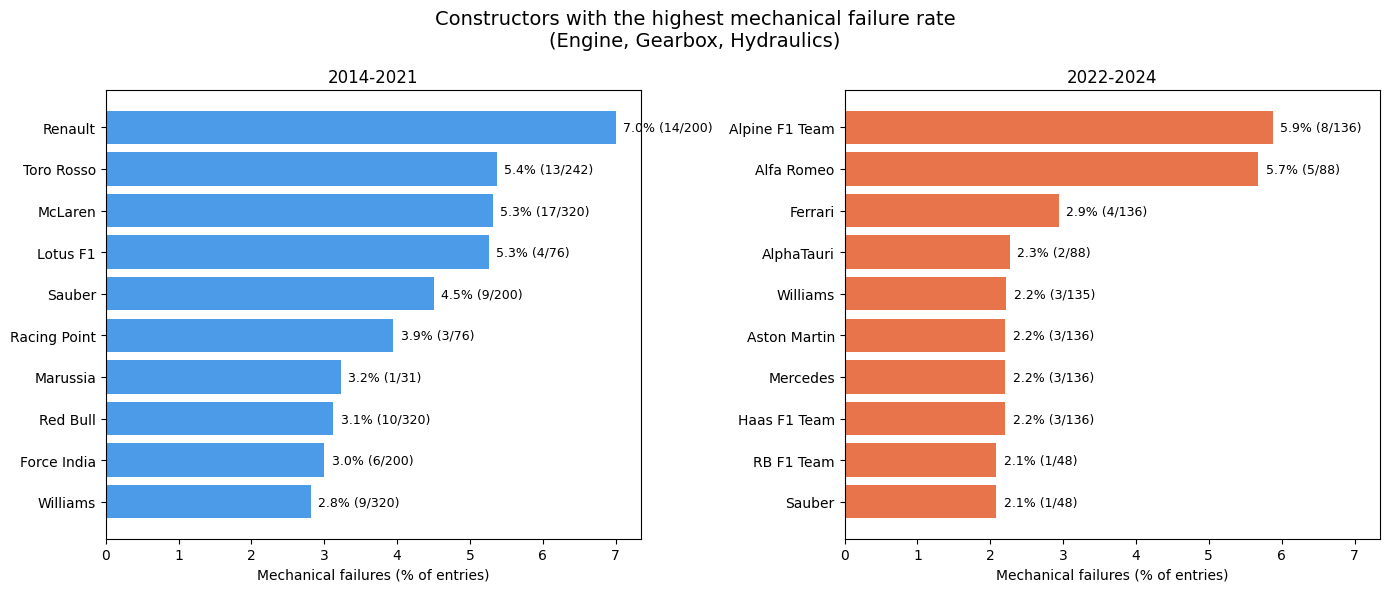

In [154]:
def failure_summary(df, start, end, min_entries=20):
    d = df[df['year'].between(start, end)]
    g = d.groupby('name').agg(
        entries=('raceId', 'size'),
        failures=('status', lambda s: s.isin(mechanical_failures).sum()),
    )
    g['rate'] = g['failures'] / g['entries'] * 100
    return g[g['entries'] >= min_entries]   # drop constructors with tiny samples

periods = [(2014, 2021, '#4c9be8'), (2022, 2024, '#e8744c')]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

for ax, (start, end, color) in zip(axes, periods):
    s = failure_summary(df, start, end).nlargest(10, 'rate').sort_values('rate')
    ax.barh(s.index, s['rate'], color=color)
    for i, (rate, n, f) in enumerate(zip(s['rate'], s['entries'], s['failures'])):
        ax.text(rate + 0.1, i, f'{rate:.1f}% ({f}/{n})', va='center', fontsize=9)
    ax.set_title(f'{start}-{end}')
    ax.set_xlabel('Mechanical failures (% of entries)')

fig.suptitle('Constructors with the highest mechanical failure rate\n(Engine, Gearbox, Hydraulics)', fontsize=14)
plt.tight_layout()
plt.show()

In [155]:
cleaned_tables['races']

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1120,1140,2024,20,32,Mexico City Grand Prix,2024-10-27,20:00:00,https://en.wikipedia.org/wiki/2024_Mexico_City...,2024-10-25,18:30:00,2024-10-25,22:00:00,2024-10-26,17:30:00,2024-10-26,21:00:00,NaN,NaN
1121,1141,2024,21,18,São Paulo Grand Prix,2024-11-03,17:00:00,https://en.wikipedia.org/wiki/2024_S%C3%A3o_Pa...,2024-11-01,14:30:00,2024-11-01,18:30:00,NaN,NaN,2024-11-02,18:00:00,2024-11-02,14:00:00
1122,1142,2024,22,80,Las Vegas Grand Prix,2024-11-23,06:00:00,https://en.wikipedia.org/wiki/2024_Las_Vegas_G...,2024-11-21,02:30:00,2024-11-21,06:00:00,2024-11-22,02:30:00,2024-11-22,06:00:00,NaN,NaN
1123,1143,2024,23,78,Qatar Grand Prix,2024-12-01,17:00:00,https://en.wikipedia.org/wiki/2024_Qatar_Grand...,2024-11-29,13:30:00,2024-11-29,17:30:00,NaN,NaN,2024-11-30,17:00:00,2024-11-30,13:00:00


# **Feature Selection & Engineering**

In [156]:
modeling_data

,raceId,round,circuitId,country,driverId,constructorId,grid,position,positionText,positionOrder,nationality
0,1,1,1,Australia,18,23,1,1.0,1,1,British
1,1,1,1,Australia,22,23,2,2.0,2,2,Brazilian
2,1,1,1,Australia,15,7,20,3.0,3,3,Italian
3,1,1,1,Australia,10,7,19,4.0,4,4,German
4,1,1,1,Australia,4,4,10,5.0,5,5,Spanish
...,...,...,...,...,...,...,...,...,...,...,...
26754,1144,24,24,UAE,825,210,14,16.0,16,16,Danish
26755,1144,24,24,UAE,859,215,12,17.0,17,17,New Zealander
26756,1144,24,24,UAE,822,15,9,NaN,R,18,Finnish
26757,1144,24,24,UAE,861,3,20,NaN,R,19,Argentinian


# **Predictive Modeling Task**